# Which orders will arrive late?

Olist, a Brazilian marketplace, promises every customer a delivery date at checkout. About **7% of delivered orders
miss it**. Operations teams can only act on a late order before it is late: by warning the customer, escalating with
the carrier, or promising a later date in the first place.

This notebook explores what makes an order late, then summarises how well a model can flag risky orders at the moment
the order is approved, using only information available at that moment.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image

sys.path.insert(0, str(Path.cwd().parent))
from ldp.features import build_dataset

df = build_dataset("../data/raw")
df = df[df["purchased_at"] >= "2017-01-01"]
print(f"{len(df):,} delivered orders, {df['late'].mean():.1%} late")

96,189 delivered orders, 6.8% late


## 1. Lateness comes in waves

The monthly late rate stays between 3% and 5% for most of 2017, then jumps in November 2017 (the Black Friday month) and again
in February and March 2018. A model trained on calm months has to cope with these waves.

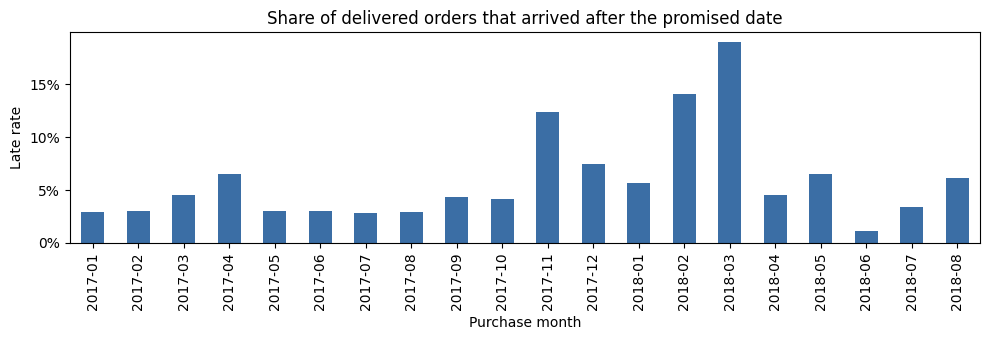

In [2]:
monthly = df.groupby(df["purchased_at"].dt.to_period("M"))["late"].mean()
ax = monthly.plot.bar(figsize=(10, 3.5), color="#3b6ea5")
ax.set_ylabel("Late rate")
ax.set_xlabel("Purchase month")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("Share of delivered orders that arrived after the promised date")
plt.tight_layout()
plt.savefig("../reports/figures/late_rate_by_month.png", dpi=150)
plt.show()

## 2. What drives it

Four things stand out, all known when the order is approved:

- **Marketplace load.** When more than 2,500 orders were placed in the previous seven days, 16.7% arrive late,
  against 3.5% below 1,000. Volume surges overwhelm sellers and carriers.
- **Distance.** Orders travelling more than 2,000 km are late 12.1% of the time; within 50 km, 4.5%.
  Crossing a state border alone moves the rate from 4.5% to 8.1%.
- **Destination.** Rio de Janeiro (12.1%) and Bahia (12.2%) are late almost three times as often as São Paulo (4.5%).
- **Seller speed.** Sellers who usually hand orders to the carrier within two days are late 4.8% of the time;
  those who take more than four days, about 8%.

Long promises protect the date: orders promised more than 40 days out are late only 2.4% of the time.

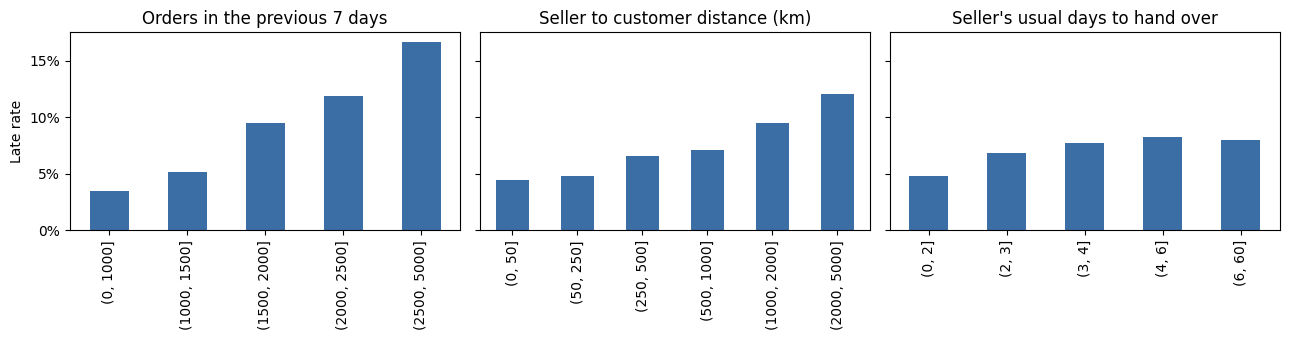

In [3]:
def rate_by(column, bins):
    return df.groupby(pd.cut(df[column], bins), observed=True)["late"].mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
panels = [
    ("orders_last_7d", [0, 1000, 1500, 2000, 2500, 5000], "Orders in the previous 7 days"),
    ("distance_km", [0, 50, 250, 500, 1000, 2000, 5000], "Seller to customer distance (km)"),
    ("seller_handling_days", [0, 2, 3, 4, 6, 60], "Seller's usual days to hand over"),
]
for ax, (column, bins, title) in zip(axes, panels):
    rate_by(column, bins).plot.bar(ax=ax, color="#3b6ea5")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].set_ylabel("Late rate")
plt.tight_layout()
plt.savefig("../reports/figures/late_rate_drivers.png", dpi=150)
plt.show()

In [4]:
top_states = df["customer_state"].value_counts().head(10).index
(df[df["customer_state"].isin(top_states)].groupby("customer_state")["late"]
   .agg(late_rate="mean", orders="size").sort_values("late_rate", ascending=False)
   .style.format({"late_rate": "{:.1%}", "orders": "{:,}"}))

,late_rate,orders
customer_state,,
BA,12.2%,"3,253"
RJ,12.1%,"12,308"
ES,10.7%,"1,992"
SC,8.2%,"3,537"
GO,6.6%,"1,950"
RS,6.1%,"5,325"
DF,5.7%,"2,074"
MG,4.6%,"11,316"
SP,4.5%,"40,394"


## 3. How well can we predict it?

`python -m ldp.train` compares logistic regression with XGBoost. Both use the same leak-free features: seller and route
history only count orders delivered before the new order was placed. Models are compared with five-fold time-series
cross-validation on January 2017 to April 2018, then tested once on May to July 2018, months they never saw. August
2018 is left out because many of its orders were still in transit when the data was exported.

Late orders are rare (3.8% in the test months), so the useful measures are PR-AUC and what happens when operations
flag the riskiest 10% of orders each day.

In [5]:
report = json.loads(Path("../reports/metrics.json").read_text())
rows = {
    name: {
        "CV ROC-AUC": m["cv_roc_auc_mean"], "CV PR-AUC": m["cv_pr_auc_mean"],
        "Test ROC-AUC": m["test_roc_auc"], "Test PR-AUC": m["test_pr_auc"],
        "Top 10%: precision": m["flag_top_10_percent"]["top_10_percent_precision"],
        "Top 10%: share of late orders caught": m["flag_top_10_percent"]["top_10_percent_recall"],
    }
    for name, m in report["models"].items()
}
print(f"Test months late rate: {report['test']['late_rate']:.1%}")
pd.DataFrame(rows).T.style.format("{:.3f}")

Test months late rate: 3.8%


,CV ROC-AUC,CV PR-AUC,Test ROC-AUC,Test PR-AUC,Top 10%: precision,Top 10%: share of late orders caught
logistic_regression,0.674,0.171,0.758,0.106,0.124,0.325
xgboost,0.673,0.181,0.711,0.098,0.112,0.295


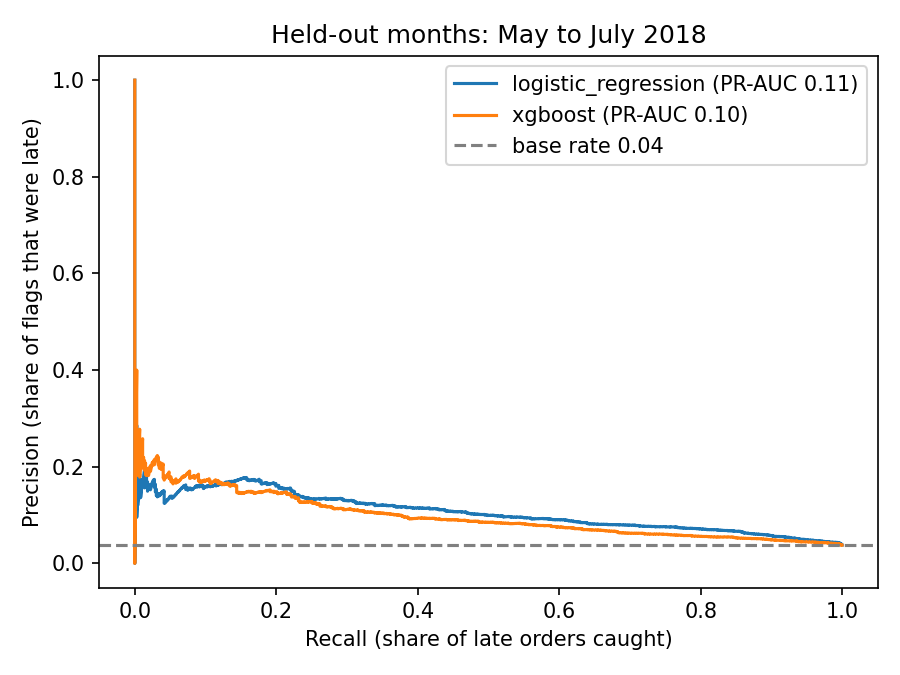

In [6]:
Image("../reports/figures/precision_recall.png", width=520)

Flagging the riskiest 10% of orders catches about a third of the orders that end up late, and a flagged order is
roughly three times as likely to be late as an average one. XGBoost had the higher cross-validated PR-AUC, so it
is the model the API serves, but logistic regression generalised better to the calmer test months. With only 16 months
of history, the simpler model is the safer default; more data would settle it.

## 4. Why the model flags an order

SHAP values show how much each feature pushed each prediction up or down. The promised delivery window dominates,
followed by marketplace load, the route's track record, the seller's handover speed and distance.

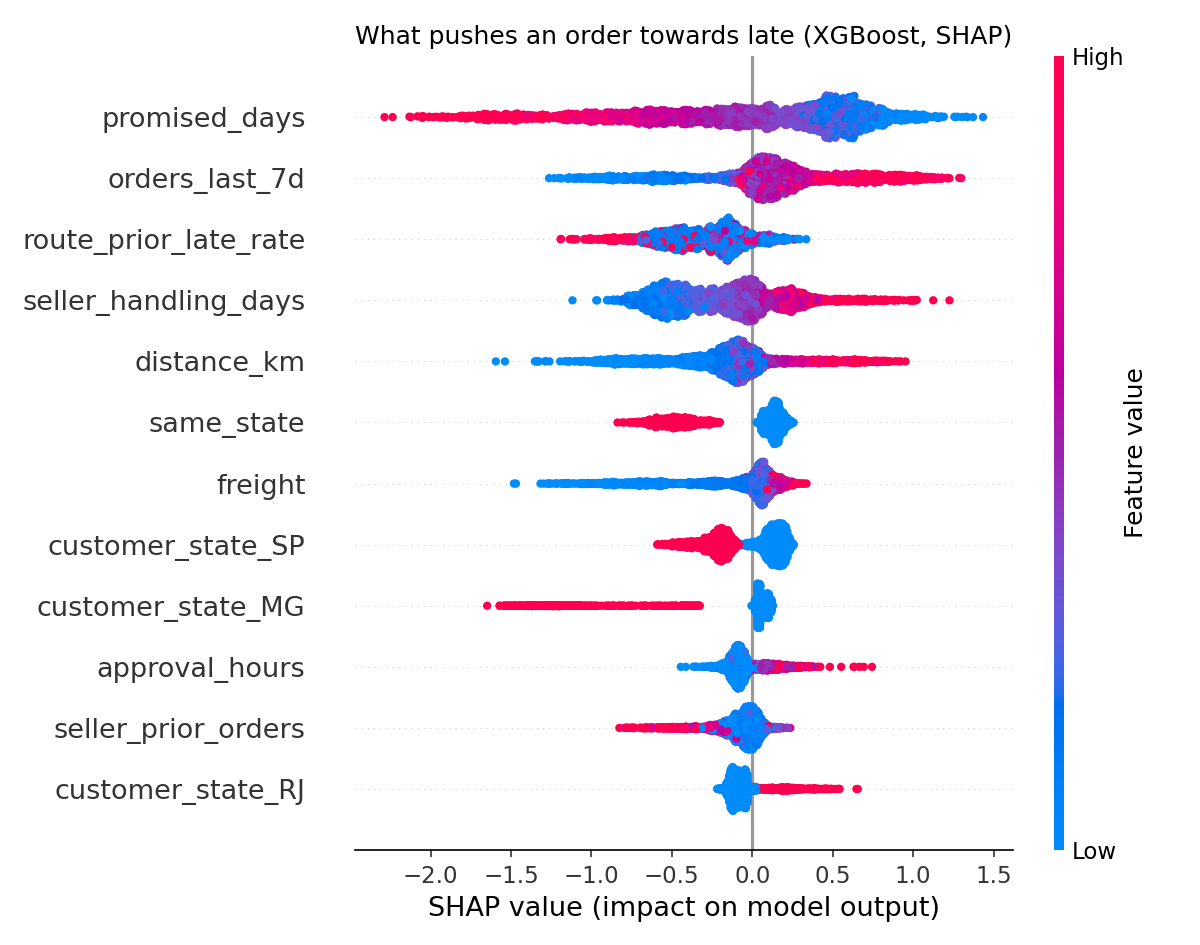

In [7]:
Image("../reports/figures/shap_summary.png", width=620)

## 5. Recommendations for operations

1. **Pad promises during surges.** When the trailing seven-day order count passes about 2,000, add buffer days to
   the promised date for cross-state orders. The late rate more than doubles above that volume.
2. **Set promises per route, not per country.** Destinations such as Rio de Janeiro, Bahia and Espírito Santo
   need longer promises from São Paulo sellers than intra-state orders do.
3. **Hold sellers to a handover target.** Sellers who take more than three days to hand over are late about 60% more
   often; a two-day handover target with a weekly scorecard addresses a cause the marketplace controls.
4. **Work a daily risk list.** Serve the model behind `POST /predict`, flag the riskiest 10% of new orders, and
   send those customers a proactive update or escalate with the carrier before the promised date passes.